# Five-Spot — volumes finitos

Quatro injetores de vazão prescrita nos cantos e um produtor central de pressão prescrita. Os parâmetros abaixo reutilizam os do notebook MDF atual; o material da Aula 12 descreve o arranjo, mas não informa todos esses valores, portanto confirme-os antes de tratar o caso como reprodução exata da aula.

Vazão positiva representa entrada no reservatório; a produção aparece negativa. O solver fornece a pressão e a vazão do produtor, e o módulo calcula as velocidades nas células a partir dos gradientes entre volumes. O balanço de massa por passo e global é calculado abaixo.

In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt

from core.permeabilidade2d import carregar_permeabilidade, gerar_permeabilidade, salvar_permeabilidade
from mvf.implicita_2d import implicita_2d
from core.velocidade2d import calcular_velocidade

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10})


In [2]:
p0 = 20.684e6
pwf = 15.0e6
q_injecao_total = 3.72e-2
Lx = Ly = 1000.0
h = 30.0
rw = 0.10
phi = 0.22
ct = 3.046e-9
mu = 1.0e-3
t_d = 10
nx = ny = 21
nt = 500

t_final = t_d * 86400
permeabilidade_file = ROOT / "data" / "permeabilidade.csv"
if permeabilidade_file.exists():
    k_mD = carregar_permeabilidade(permeabilidade_file)
else:
    k_mD = gerar_permeabilidade(nx, ny, 50, 500, seed=42)
    salvar_permeabilidade(k_mD, permeabilidade_file)
k = k_mD * 9.869233e-16
iw = nx // 2
jw = ny // 2
injection_wells = [
    {"i": 0, "j": 0, "rate": q_injecao_total / 4},
    {"i": nx - 1, "j": 0, "rate": q_injecao_total / 4},
    {"i": 0, "j": ny - 1, "rate": q_injecao_total / 4},
    {"i": nx - 1, "j": ny - 1, "rate": q_injecao_total / 4},
]

RESULTS_DIR = ROOT / "results" / "mvf" / "five_spot"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

x, y, t, P, q_produtor = implicita_2d(
    p0, pwf, rw, h, Lx, Ly, k, phi, ct, mu, t_final, nx, ny, nt,
    iw=iw, jw=jw, injection_wells=injection_wells,
)
Vx, Vy, V = calcular_velocidade(P, k, mu, Lx / nx, Ly / ny, h=h)
q_injetores = np.full((len(injection_wells), len(t)), q_injecao_total / 4)
q_producao = np.maximum(-q_produtor, 0.0)
Q_acumulada = np.zeros_like(t)
Q_acumulada[1:] = np.cumsum(0.5 * (q_producao[:-1] + q_producao[1:]) * np.diff(t))


Maior resíduo absoluto por passo: 1.702229e-10 m³
Resíduo global ao final: -3.340701e-09 m³
Variação armazenada ao final: -3.268316e+03 m³
Volume líquido acumulado: -3.268316e+03 m³


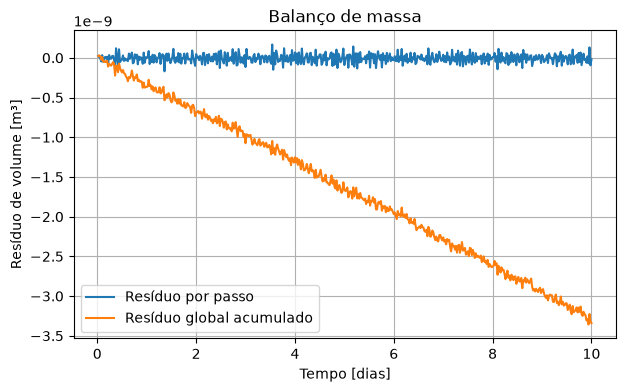

In [3]:
# Balanço de massa por passo e acumulado
# Vazões positivas entram no reservatório; q_produtor é negativo para produção.
volume_celula = (Lx / nx) * (Ly / ny) * h
armazenamento = phi * ct * volume_celula * (P.sum(axis=(1, 2)) - P[0].sum())
vazao_injecao = sum(poco["rate"] for poco in injection_wells)
vazao_liquida = vazao_injecao + q_produtor
dt_passos = np.diff(t)
volume_liquido_passo = vazao_liquida[1:] * dt_passos
variacao_armazenada_passo = np.diff(armazenamento)
residuo_passo = variacao_armazenada_passo - volume_liquido_passo
residuo_global = np.cumsum(residuo_passo)

print(f"Maior resíduo absoluto por passo: {np.max(np.abs(residuo_passo)):.6e} m³")
print(f"Resíduo global ao final: {residuo_global[-1]:.6e} m³")
print(f"Variação armazenada ao final: {armazenamento[-1]:.6e} m³")
print(f"Volume líquido acumulado: {np.sum(volume_liquido_passo):.6e} m³")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t[1:] / 86400, residuo_passo, label="Resíduo por passo")
ax.plot(t[1:] / 86400, residuo_global, label="Resíduo global acumulado")
ax.set(xlabel="Tempo [dias]", ylabel="Resíduo de volume [m³]", title="Balanço de massa")
ax.grid()
ax.legend()
plt.show()


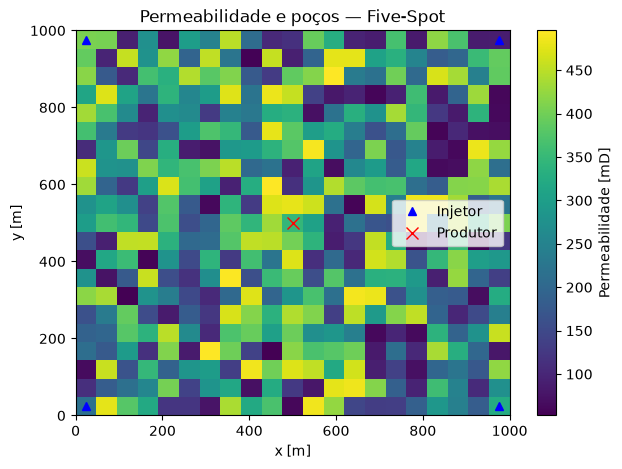

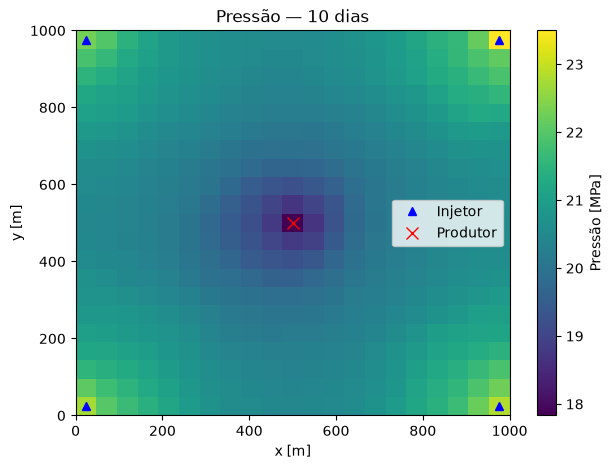

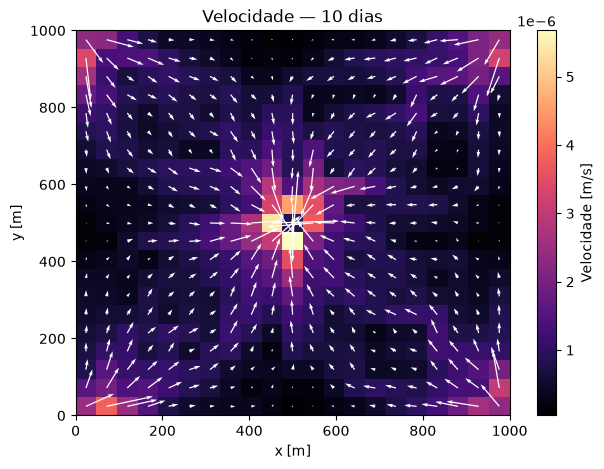

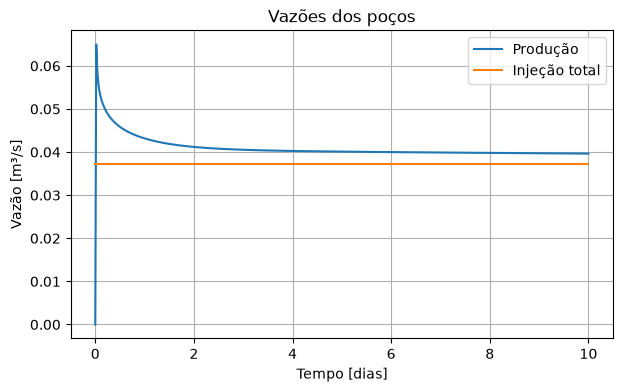

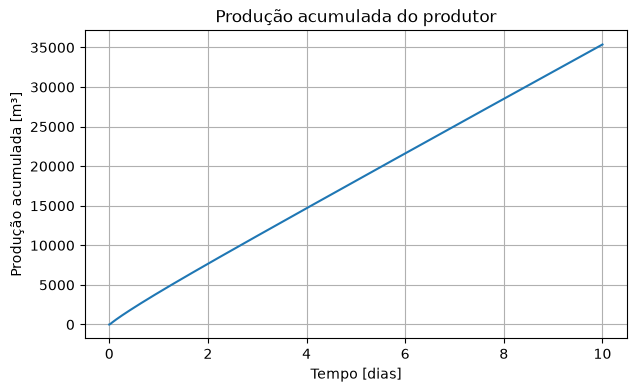

In [4]:
X, Y = np.meshgrid(x, y)

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.pcolormesh(X, Y, k_mD, shading="auto", cmap="viridis")
fig.colorbar(image, ax=ax, label="Permeabilidade [mD]")
for index, well in enumerate(injection_wells):
    ax.plot(x[well["i"]], y[well["j"]], "b^", label="Injetor" if index == 0 else None)
ax.plot(x[iw], y[jw], "rx", markersize=9, label="Produtor")
ax.set(xlabel="x [m]", ylabel="y [m]", title="Permeabilidade e poços — Five-Spot")
ax.legend()
fig.savefig(RESULTS_DIR / "permeabilidade_pocos.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.pcolormesh(X, Y, P[-1] / 1e6, shading="auto", cmap="viridis")
fig.colorbar(image, ax=ax, label="Pressão [MPa]")
for index, well in enumerate(injection_wells):
    ax.plot(x[well["i"]], y[well["j"]], "b^", label="Injetor" if index == 0 else None)
ax.plot(x[iw], y[jw], "rx", markersize=9, label="Produtor")
ax.set(xlabel="x [m]", ylabel="y [m]", title=f"Pressão — {t[-1] / 86400:g} dias")
ax.legend()
fig.savefig(RESULTS_DIR / "pressao_final.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.pcolormesh(X, Y, V[-1], shading="auto", cmap="magma")
fig.colorbar(image, ax=ax, label="Velocidade [m/s]")
step = max(1, nx // 12)
ax.quiver(X[::step, ::step], Y[::step, ::step], Vx[-1, ::step, ::step], Vy[-1, ::step, ::step], color="white")
ax.set(xlabel="x [m]", ylabel="y [m]", title=f"Velocidade — {t[-1] / 86400:g} dias")
fig.savefig(RESULTS_DIR / "velocidade_final.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t / 86400, q_producao, label="Produção")
ax.plot(t / 86400, q_injetores.sum(axis=0), label="Injeção total")
ax.set(xlabel="Tempo [dias]", ylabel="Vazão [m³/s]", title="Vazões dos poços")
ax.grid()
ax.legend()
fig.savefig(RESULTS_DIR / "vazoes_pocos.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t / 86400, Q_acumulada)
ax.set(xlabel="Tempo [dias]", ylabel="Produção acumulada [m³]", title="Produção acumulada do produtor")
ax.grid()
fig.savefig(RESULTS_DIR / "producao_acumulada.pdf", bbox_inches="tight")
plt.show()


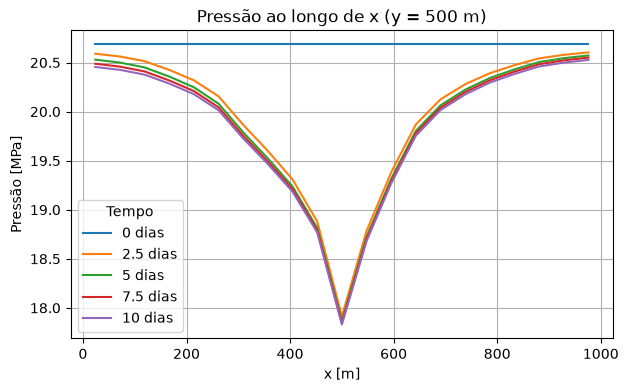

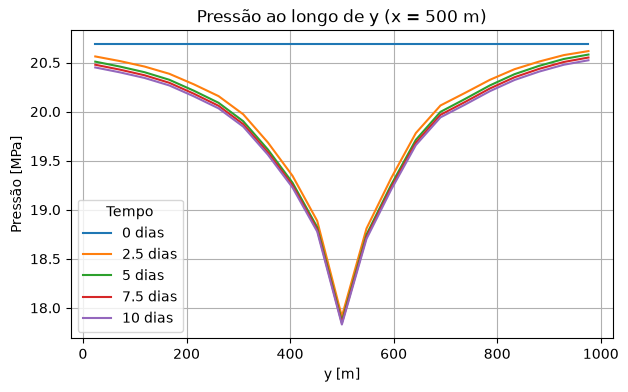

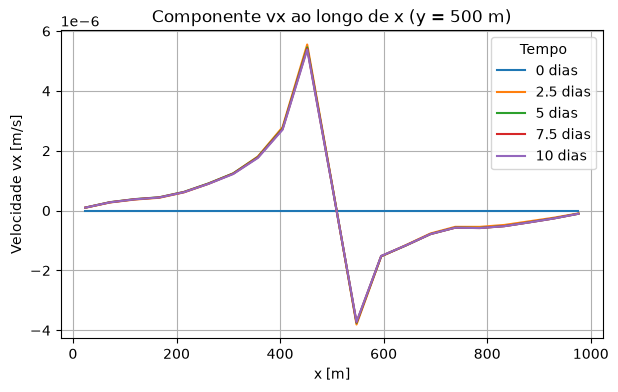

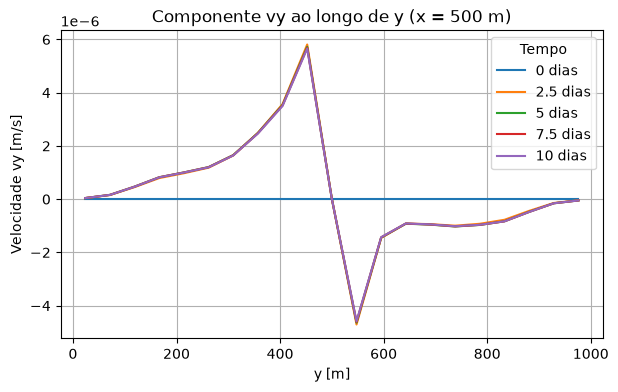

In [5]:
# Perfis transientes ao longo das linhas centrais do reservatório
indices_tempo = np.unique(np.linspace(0, len(t) - 1, 5, dtype=int))
j_central = ny // 2
i_central = nx // 2

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(x, P[indice, j_central, :] / 1e6, label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="x [m]", ylabel="Pressão [MPa]", title=f"Pressão ao longo de x (y = {y[j_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "pressao_transiente_x.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(y, P[indice, :, i_central] / 1e6, label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="y [m]", ylabel="Pressão [MPa]", title=f"Pressão ao longo de y (x = {x[i_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "pressao_transiente_y.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(x, Vx[indice, j_central, :], label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="x [m]", ylabel="Velocidade vx [m/s]", title=f"Componente vx ao longo de x (y = {y[j_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "velocidade_transiente_x.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for indice in indices_tempo:
    ax.plot(y, Vy[indice, :, i_central], label=f"{t[indice] / 86400:g} dias")
ax.set(xlabel="y [m]", ylabel="Velocidade vy [m/s]", title=f"Componente vy ao longo de y (x = {x[i_central]:g} m)")
ax.grid()
ax.legend(title="Tempo")
fig.savefig(RESULTS_DIR / "velocidade_transiente_y.pdf", bbox_inches="tight")
plt.show()
